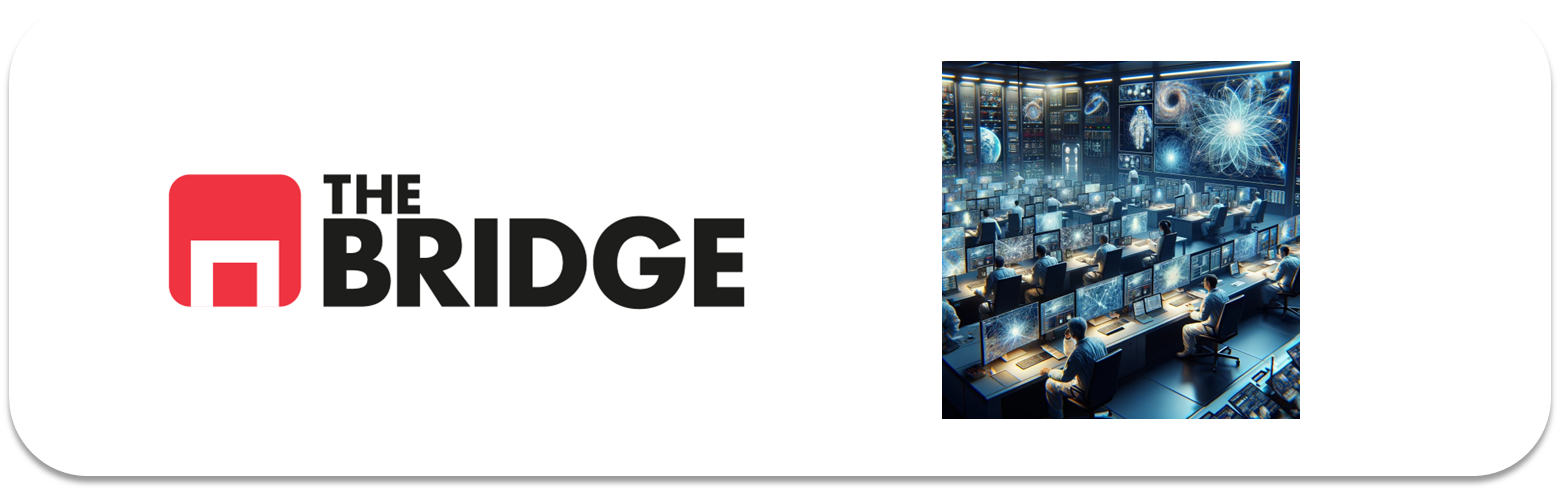

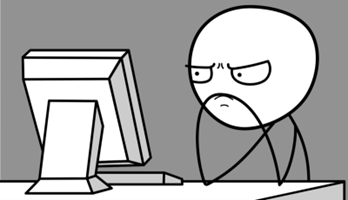

Para ejercitarte y afianzar lo aprendido sobre **Transfer Learning y Fine-tuning**, completa los siguientes ejercicios. Los datos están comprimidos en el fichero `apples.zip` del directorio `data` de la unidad (en el Ejercicio 1 lo descomprimirás desde el propio notebook).

Ya tienes la solución, pero intenta hacerlo por tu cuenta antes de consultarla.

> Los entrenamientos de este notebook son pesados si no tienes GPU (en un portátil sin GPU, entre una y dos horas en total). Puedes reducir el número de épocas si vas justo de tiempo.

### Ejercicio 0

Importa los paquetes y módulos que necesites a lo largo del notebook

In [1]:
import os
import zipfile
from time import time

import cv2
import keras
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from keras.applications.resnet_v2 import ResNet50V2, decode_predictions, preprocess_input
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
from sklearn.utils import shuffle

keras.utils.set_random_seed(42) # Para que los entrenamientos sean (casi) reproducibles

## Fruits 360: manzanas

En este conjunto de ejercicios vas a montar un clasificador de manzanas mediante un dataset de imágenes. El dataset se compone de 13 variedades diferentes, con unas 490 imágenes por variedad en train y unas 165 en test, todas a color y de 100x100 píxeles. Tendrás que montar un modelo de deep learning que utilice **transfer learning**. Se sugiere emplear una red ResNet50V2 preentrenada con ImageNet.

El clasificador debe incluir también ***image augmentation*** para que se entrene con una mayor variedad de casos y perspectivas de las frutas.

El dataset original proviene del dataset de Kaggle [Fruits 360](https://www.kaggle.com/datasets/moltean/fruits), adaptado para clasificar una menor cantidad de casos (solo las manzanas). Un detalle importante sobre cómo se creó: cada manzana se grabó en vídeo girando sobre sí misma y las imágenes son fotogramas de esos vídeos, así que **muchas imágenes de train son casi idénticas entre sí**. Tenlo en cuenta al interpretar los resultados de validación.

### Ejercicio 1

Descomprime `../data/apples.zip` (solo si no está ya descomprimido) y explora la estructura de directorios. Crea los juegos X, y de train y test a 100x100 (la resolución original) y un juego de test adicional a 224x224, que usarás en el Ejercicio 6. Es decir, tendrás que tener un X_train, X_test a 100x100 y un X_test_224 adicional.

In [2]:
DATA_PATH = "../data"

# Descomprimimos solo la primera vez (la carpeta apples/ está en el .gitignore del repositorio)
if not os.path.isdir(os.path.join(DATA_PATH, "apples")):
    with zipfile.ZipFile(os.path.join(DATA_PATH, "apples.zip")) as zip_file:
        zip_file.extractall(DATA_PATH)

TRAIN_PATH = os.path.join(DATA_PATH, "apples", "Train")
TEST_PATH = os.path.join(DATA_PATH, "apples", "Test")
print(os.listdir(os.path.join(DATA_PATH, "apples")))
print(sorted(os.listdir(TRAIN_PATH)))

['Test', 'Train']
['Braeburn', 'CrimsonSnow', 'Golden1', 'Golden2', 'Golden3', 'GrannySmith', 'PinkLady', 'Red1', 'Red2', 'Red3', 'RedDelicious', 'RedYellow1', 'RedYellow2']


*Un subdirectorio por variedad, tanto en train como en test. Creamos una función que recorra los subdirectorios, lea cada imagen, la redimensione y guarde como etiqueta el nombre de su carpeta:*

In [3]:
def read_data(path, size = (100, 100)):
    X = []
    y = []
    for category in sorted(os.listdir(path)):
        for file in sorted(os.listdir(os.path.join(path, category))):
            img = plt.imread(os.path.join(path, category, file))
            X.append(cv2.resize(img, size))
            y.append(category)
    return np.array(X), np.array(y)

X_train, y_train = read_data(TRAIN_PATH)
X_test, y_test = read_data(TEST_PATH)
X_test_224, y_test_224 = read_data(TEST_PATH, (224, 224))

print(X_train.shape, y_train.shape, X_train.dtype)
print(X_test.shape, y_test.shape)
print(X_test_224.shape, y_test_224.shape)

(6404, 100, 100, 3) (6404,) uint8
(2134, 100, 100, 3) (2134,)
(2134, 224, 224, 3) (2134,)


*6404 imágenes de train y 2134 de test, a color (3 canales) y con los píxeles como enteros entre 0 y 255. El juego a 224x224 lo usaremos para probar ResNet50V2 tal cual, que con su cabeza original exige ese tamaño.*

**NOTA:** A partir de aquí emplea siempre el X_train, X_test de 100x100 salvo en el ejercicio en que se te indique lo contrario.

### Ejercicio 2

Haz una visualización de algunos de los datos. Crea una función que te ayude con ello.

*Creamos una función que espera "batches" de imágenes en formato numpy array:*

In [4]:
def show_images_batch(apples, names = [], n_cols = 5, size_scale = 2):
    n_rows = ((len(apples) - 1) // n_cols + 1)
    plt.figure(figsize=(n_cols * size_scale, n_rows * 1.1 * size_scale))
    for index, apple in enumerate(apples):
        plt.subplot(n_rows, n_cols, index + 1)
        plt.imshow(apple)
        plt.axis("off")
        if len(names):
            plt.title(names[index])
    plt.show()

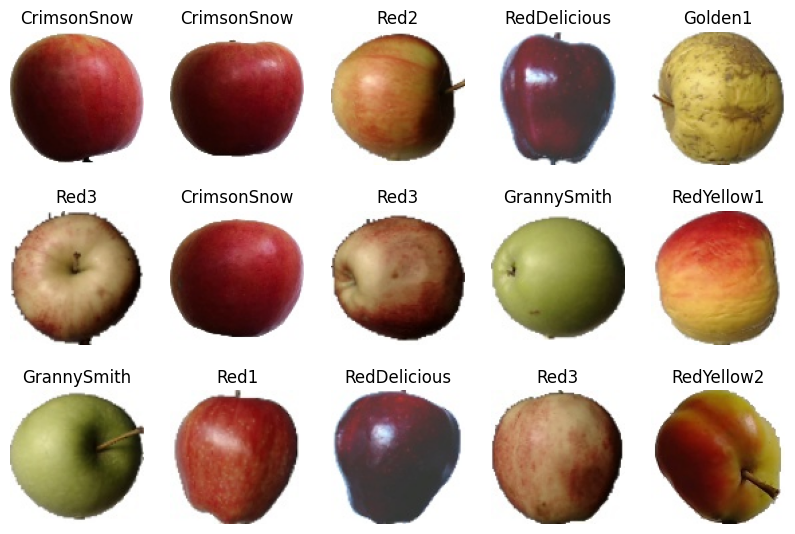

In [5]:
rng = np.random.default_rng(42)
indices = rng.choice(len(X_train), 15, replace=False)
show_images_batch(X_train[indices], y_train[indices])

*Y una manzana de cada variedad, para ver lo parecidas que son algunas entre sí:*

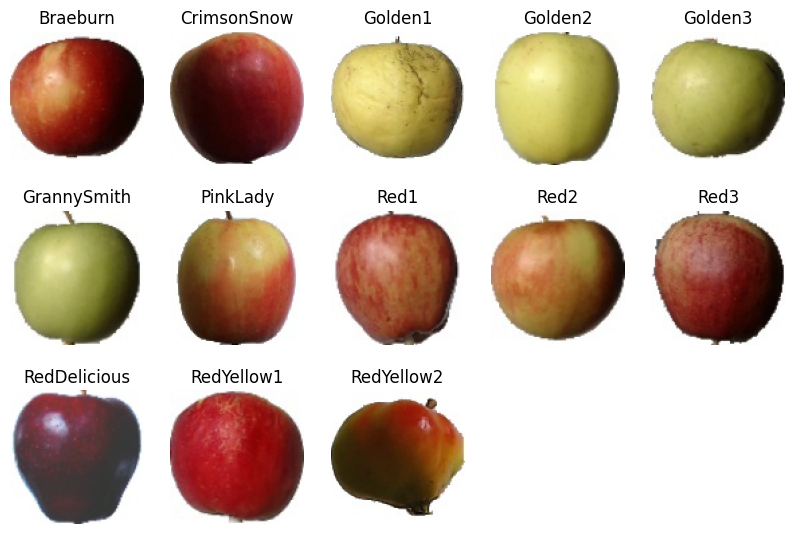

In [6]:
primeras = [np.where(y_train == variedad)[0][0] for variedad in np.unique(y_train)]
show_images_batch(X_train[primeras], y_train[primeras])

*Veamos también algunas de test a 224x224:*

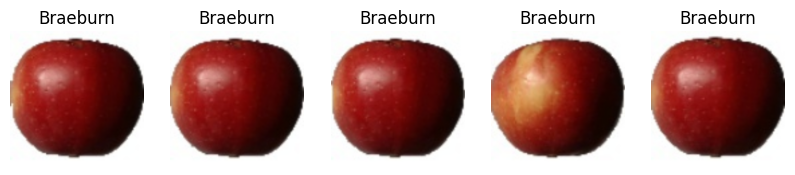

In [7]:
show_images_batch(X_test_224[23:28], y_test_224[23:28])

### Ejercicio 3

Completa el miniEDA habitual con imágenes y escoge una métrica para el modelo.

In [8]:
pd.Series(y_train).value_counts(normalize = True)

RedYellow2      0.104934
Braeburn        0.076827
Golden2         0.076827
GrannySmith     0.076827
Red1            0.076827
Red2            0.076827
RedYellow1      0.076827
RedDelicious    0.076515
Golden3         0.075109
Golden1         0.074953
PinkLady        0.071205
CrimsonSnow     0.069332
Red3            0.066989
Name: proportion, dtype: float64

*Tenemos 13 clases con una distribución bastante uniforme, salvo RedYellow2, que es algo más numerosa (un 10 % frente al 7-8 % del resto). No es un desequilibrio preocupante, así que emplearemos la accuracy como métrica, apoyándonos además en el informe de clasificación para ver qué tal va cada variedad.*

### Ejercicio 4

Termina de preparar los datos:

* ResNet50V2 espera los píxeles escalados entre -1 y 1, que es lo que hace su función `preprocess_input`. Decide si aplicarla directamente a los arrays o incluirla como una capa más del modelo (lo haremos en el Ejercicio 7).
* Baraja el X_train (del X_test no es necesario) con la función `shuffle` de sklearn y asigna la salida a un X_train distinto (es decir, no machaques el inicial). Keras ya baraja los datos de entrenamiento en cada época: ¿por qué es entonces imprescindible barajar si vamos a usar `validation_split`?

*Respecto al escalado, en lugar de dividir entre 255 (que dejaría los píxeles en [0, 1], un rango distinto del que ResNet50V2 vio en su preentrenamiento) usaremos su `preprocess_input`, que los lleva a [-1, 1]. Lo meteremos **dentro del modelo**, así que los arrays se quedan como están, en enteros de 0 a 255 (además ocupan 4 veces menos memoria que en float32).*

*Respecto al barajado: `validation_split` **no baraja**, se queda siempre con el último 20 % de los datos que le pasamos. Como hemos leído las imágenes carpeta a carpeta, nuestros datos están ordenados por variedad y sin barajar la validación serían solo las últimas variedades (RedYellow1 y RedYellow2), que el modelo no vería nunca al entrenar.*

In [9]:
X_train_s, y_train_s = shuffle(X_train, y_train, random_state=42)
print(y_train[-5:], y_train_s[-5:])

['RedYellow2' 'RedYellow2' 'RedYellow2' 'RedYellow2' 'RedYellow2'] ['Red1' 'RedDelicious' 'RedDelicious' 'RedYellow1' 'CrimsonSnow']


### Ejercicio 5

Sklearn permite trabajar con etiquetas textuales pero Keras no. Transforma las etiquetas a numéricas, creando dos diccionarios: uno que permita traducir de etiqueta a clase numérica y otro que permita la transformación inversa.

In [10]:
categorias = np.unique(y_train)
n_categorias = len(categorias)

mapping = {cat: i for i, cat in enumerate(categorias)}
inverse_mapping = {valor: clave for clave, valor in mapping.items()}
mapping

{'Braeburn': 0,
 'CrimsonSnow': 1,
 'Golden1': 2,
 'Golden2': 3,
 'Golden3': 4,
 'GrannySmith': 5,
 'PinkLady': 6,
 'Red1': 7,
 'Red2': 8,
 'Red3': 9,
 'RedDelicious': 10,
 'RedYellow1': 11,
 'RedYellow2': 12}

In [11]:
y_train_num = np.array([mapping[cat] for cat in y_train_s])
y_test_num = np.array([mapping[cat] for cat in y_test])

### Ejercicio 6: usar ResNet50V2 tal cual, sin reentrenar

Descarga el modelo ResNet50V2 completo, con su cabeza de clasificación original (`include_top=True`), y úsalo directamente sobre el test de 224x224 (no olvides aplicar su `preprocess_input`). Ojo: aquí no valen nuestras categorías, el modelo responde con alguna de las 1000 clases de ImageNet. Prueba una selección aleatoria de imágenes del test y compara las etiquetas de ResNet con las reales. ¿Nos sirve este clasificador tal cual?

> Esto **no** es *zero-shot learning*: en zero-shot el modelo clasifica en categorías nuevas a partir de su descripción, algo que requiere modelos como los LLM o CLIP. Una CNN con 1000 clases fijas solo puede contestar con esas clases.

In [12]:
modelo_imagenet = ResNet50V2(include_top=True, weights="imagenet")

1/1 ━━━━━━━━━━━━━━━━━━━━ 5s 5s/step


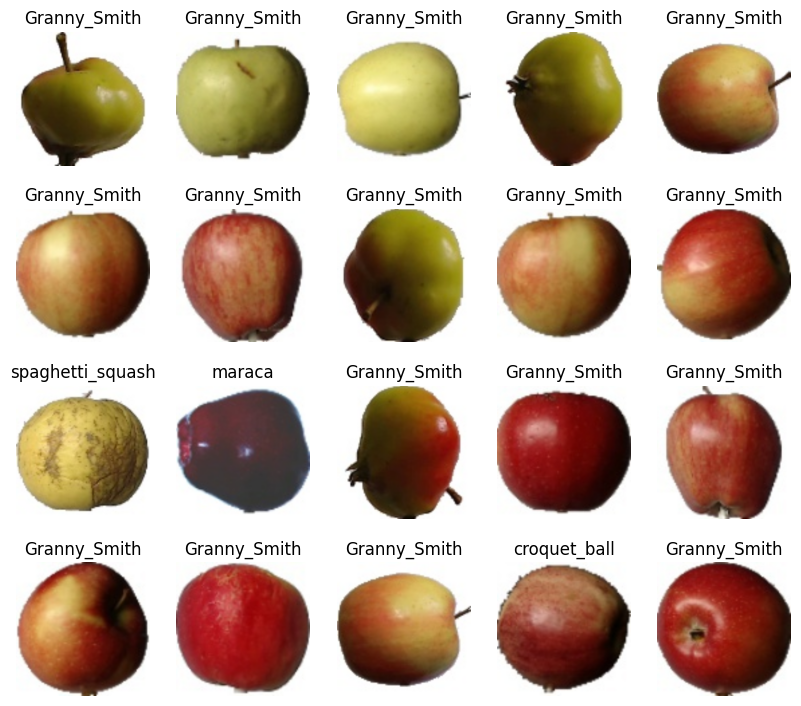

In [13]:
seleccion = np.random.default_rng(0).choice(len(X_test_224), 20, replace=False)
predictions = modelo_imagenet.predict(preprocess_input(X_test_224[seleccion].astype("float32")))
clase = [decodificado[0][1] for decodificado in decode_predictions(predictions, top=1)]
show_images_batch(X_test_224[seleccion], names = clase)

*Para tener una visión de conjunto, predecimos todo el test y vemos, para cada variedad, cuál es la clase de ImageNet que más predice y en qué proporción:*

In [14]:
preds_imagenet = modelo_imagenet.predict(preprocess_input(X_test_224.astype("float32")), batch_size=64)
top1 = [decodificado[0][1] for decodificado in decode_predictions(preds_imagenet, top=1)]

resumen = pd.crosstab(y_test_224, np.array(top1), normalize="index")
pd.DataFrame({"clase ImageNet más predicha": resumen.idxmax(axis=1),
              "proporción": resumen.max(axis=1).round(2)})

34/34 ━━━━━━━━━━━━━━━━━━━━ 175s 5s/step


,clase ImageNet más predicha,proporción
row_0,,
Braeburn,Granny_Smith,1.00
CrimsonSnow,Granny_Smith,0.99
Golden1,spaghetti_squash,0.64
Golden2,Granny_Smith,1.00
Golden3,Granny_Smith,1.00
GrannySmith,Granny_Smith,1.00
PinkLady,Granny_Smith,0.99
Red1,Granny_Smith,0.98
Red2,Granny_Smith,1.00


*Un pequeño... desastre, aunque muy instructivo. ImageNet tiene **una sola clase de manzana**, `Granny_Smith`, así que la red llama Granny Smith a prácticamente todas nuestras manzanas, sean verdes, amarillas o rojas (en 10 de las 13 variedades es la clase más predicha, y en la mayoría con un 98-100 %). Cuando no, contesta con lo que más se le parece de entre sus 1000 clases: las Golden1 son `spaghetti_squash` (una calabaza amarilla) y las RedDelicious, `buckeye` (castaña de Indias).*

*Acierta todas las Granny Smith, pero eso no vale de nada si también llama Granny Smith a todo lo demás. El modelo no puede distinguir variedades que no estaban entre sus clases: necesitamos transfer learning.*

In [15]:
del modelo_imagenet, preds_imagenet, X_test_224 # Liberamos memoria, no los vamos a usar más

## Transfer Learning (fase 1: extracción de características)

### Ejercicio 7

Carga la ResNet50V2 sin cabeza (`include_top=False`), con los pesos de ImageNet y para imágenes de 100x100, y congela todas sus capas. Crea un modelo con la API funcional que incluya, en este orden:

* Aumentado de imágenes con capas de Keras (por ejemplo `RandomFlip`, `RandomRotation` y `RandomZoom`).
* El `preprocess_input` de ResNet50V2.
* El modelo base, llamado con `training=False` (¿por qué?).
* Una capa `GlobalAveragePooling2D`.
* Una cabeza con dos capas densas: una oculta de 300 unidades con activación "relu" (y un Dropout si lo consideras) y otra de salida con las unidades y la activación que creas necesarias.

Define también los hiperparámetros necesarios para compilar, compila el modelo y muestra un summary del mismo.

*Creamos el modelo dentro de una función que construye **una base nueva en cada llamada**. Es importante: si reutilizáramos el mismo objeto `base_model` entre modelos, todos compartirían sus pesos y cualquier entrenamiento (incluido uno de prueba) modificaría los pesos de los demás. La función nos servirá también para el EXTRA final.*

*La base se llama con `training=False` para que sus capas de BatchNormalization trabajen siempre en modo inferencia, con las estadísticas de ImageNet, incluso cuando más adelante las descongelemos para el fine-tuning.*

In [16]:
IMG_SIZE = 100

def prepare_model(weights = "imagenet"):
    base_model = ResNet50V2(include_top=False, weights=weights, input_shape=(IMG_SIZE, IMG_SIZE, 3))

    aumentado = keras.Sequential([
        keras.layers.RandomFlip("horizontal_and_vertical"), # Una manzana girada sigue siendo la misma manzana
        keras.layers.RandomRotation(0.2),
        keras.layers.RandomZoom(0.1),
    ], name="aumentado")

    inputs = keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
    x = aumentado(inputs)
    x = preprocess_input(x) # [0, 255] -> [-1, 1]
    if weights is None: # Desde cero (EXTRA): toda la red se entrena y BatchNorm debe aprender sus estadísticas
        x = base_model(x)
    else: # Transfer learning: base congelada y BatchNorm siempre en modo inferencia
        base_model.trainable = False
        x = base_model(x, training=False)
    x = keras.layers.GlobalAveragePooling2D()(x)
    x = keras.layers.Dense(300, activation="relu")(x)
    x = keras.layers.Dropout(0.5)(x)
    outputs = keras.layers.Dense(n_categorias, activation="softmax")(x) # 13 clases

    model = keras.Model(inputs, outputs)
    model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model, base_model

model, base_model = prepare_model()
model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 100, 100, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ aumentado (Sequential)          │ (None, 100, 100, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 100, 100, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract (Subtract)             │ (None, 100, 100, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50v2 (Functional)         │ (None, 4, 4, 2048)     │    23,564,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 300)            │       614,700 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 300)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 13)             │         3,913 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 24,183,413 (92.25 MB)

 Trainable params: 618,613 (2.36 MB)

 Non-trainable params: 23,564,800 (89.89 MB)

*Solo son entrenables los parámetros de la cabeza (unos 600.000); los más de 23 millones de la ResNet están congelados con los pesos de ImageNet. Usamos `sparse_categorical_crossentropy` porque el target es un entero por clase.*

### Ejercicio 8

Entrena el modelo con nuestros datos de train reservando un 20 % para validación y muestra la evolución del entrenamiento. Emplea un callback de EarlyStopping con patience a 5. Termina de escoger el batch_size y el número de épocas.

*Para escoger el batch_size (si no queremos usar el "clásico" 32) vemos cuántas actualizaciones de pesos (steps) haría cada época con el 80 % de train:*

In [17]:
instancias_train = len(X_train_s) * 0.8
for i in range(1, 5):
    print(f"Batch_size: {32*i}, num_steps_per_epoch: {round(instancias_train/(32*i))}")

Batch_size: 32, num_steps_per_epoch: 160
Batch_size: 64, num_steps_per_epoch: 80
Batch_size: 96, num_steps_per_epoch: 53
Batch_size: 128, num_steps_per_epoch: 40


*Vamos con batches de 64, unos 80 steps por época, y hasta 20 épocas: el EarlyStopping (con `restore_best_weights` para quedarnos con la mejor época) decidirá cuándo parar.*

In [18]:
batch_size = 64
early_stopping = keras.callbacks.EarlyStopping(patience=5, restore_best_weights=True)

t_zero = time()
history = model.fit(X_train_s,
                    y_train_num,
                    batch_size=batch_size,
                    validation_split=0.2,
                    epochs=20,
                    callbacks=[early_stopping])
print(f"Tiempo de entrenamiento: {time() - t_zero:.0f} s")

Epoch 1/20
81/81 ━━━━━━━━━━━━━━━━━━━━ 92s 962ms/step - accuracy: 0.5255 - loss: 1.8720 - val_accuracy: 0.8993 - val_loss: 0.3314
Epoch 2/20
81/81 ━━━━━━━━━━━━━━━━━━━━ 86s 1s/step - accuracy: 0.8640 - loss: 0.3948 - val_accuracy: 0.9415 - val_loss: 0.1973
Epoch 3/20
81/81 ━━━━━━━━━━━━━━━━━━━━ 93s 1s/step - accuracy: 0.8969 - loss: 0.3098 - val_accuracy: 0.9680 - val_loss: 0.1186
Epoch 4/20
81/81 ━━━━━━━━━━━━━━━━━━━━ 92s 1s/step - accuracy: 0.9223 - loss: 0.2205 - val_accuracy: 0.9750 - val_loss: 0.0959
Epoch 5/20
81/81 ━━━━━━━━━━━━━━━━━━━━ 92s 1s/step - accuracy: 0.9332 - loss: 0.1933 - val_accuracy: 0.9664 - val_loss: 0.1172
Epoch 6/20
81/81 ━━━━━━━━━━━━━━━━━━━━ 88s 1s/step - accuracy: 0.9455 - loss: 0.1590 - val_accuracy: 0.9813 - val_loss: 0.0687
Epoch 7/20
81/81 ━━━━━━━━━━━━━━━━━━━━ 141s 1s/step - accuracy: 0.9532 - loss: 0.1348 - val_accuracy: 0.9657 - val_loss: 0.0963
Epoch 8/20
81/81 ━━━━━━━━━━━━━━━━━━━━ 78s 964ms/step - accuracy: 0.9457 - loss: 0.1464 - val_accuracy: 0.9477 - va

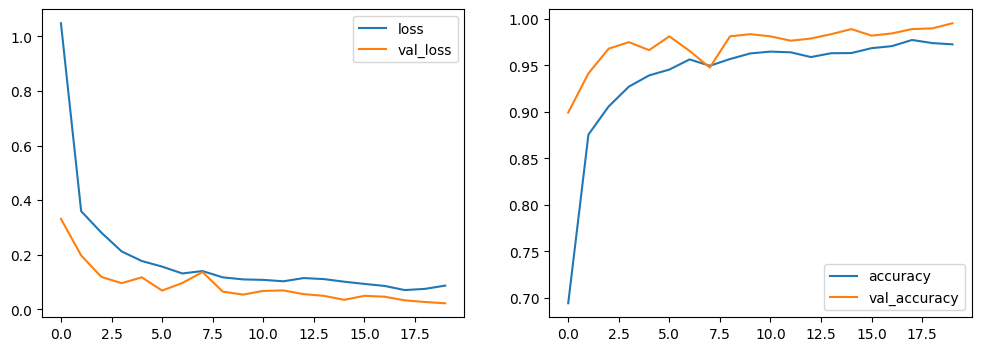

In [19]:
evol = pd.DataFrame(history.history)
fig, axs = plt.subplots(1, 2, figsize=(12, 4))
evol[["loss", "val_loss"]].plot(ax=axs[0])
evol[["accuracy", "val_accuracy"]].plot(ax=axs[1])
plt.show()

*La base congelada da muy buen resultado desde el principio: la validación arranca en un 90 % en la primera época, supera el 95 % en la tercera y sigue mejorando hasta la época 20 (el EarlyStopping no ha llegado a saltar, así que podríamos haber entrenado alguna época más), con un 99,5 % de accuracy en validación. La accuracy de train queda por debajo de la de validación porque en train el modelo ve imágenes aumentadas y con Dropout.*

*Un 99,5 % en validación parece demasiado bueno para ser verdad, y lo es. Lo veremos al evaluar contra test.*

### Ejercicio 9

Evalúa el modelo contra test y haz un pequeño análisis de las diferencias con validación. Haz un classification report y muestra la matriz de confusión. Haz un pequeño análisis de errores.

In [20]:
results_tl = model.evaluate(X_test, y_test_num)
print("test loss, test acc:", results_tl)

67/67 ━━━━━━━━━━━━━━━━━━━━ 17s 252ms/step - accuracy: 0.9248 - loss: 0.2968
test loss, test acc: [0.27837735414505005, 0.9175257682800293]


*Un 91,8 % en test, frente al 99,5 % de validación. No es el sobreajuste "de libro" (la accuracy de train incluso está por debajo de la de validación): es que **la validación es demasiado optimista**. Como te contábamos al principio, las imágenes son fotogramas de vídeo de cada manzana girando, así que al separar la validación al azar casi cada imagen de validación tiene en train fotogramas vecinos prácticamente idénticos. El test, en cambio, son fotogramas de otras grabaciones.*

*La lección es importante: la validación debe parecerse a cómo usaremos el modelo (aquí, separando por vídeo o por manzana, si tuviéramos ese dato). Con este dataset solo el test nos da una estimación realista, y precisamente por eso lo reservamos para el final y no lo usamos para tomar decisiones.*

In [21]:
y_pred = np.array([inverse_mapping[i] for i in np.argmax(model.predict(X_test), axis=1)])
print(classification_report(y_test, y_pred))

67/67 ━━━━━━━━━━━━━━━━━━━━ 25s 321ms/step
              precision    recall  f1-score   support

    Braeburn       0.89      1.00      0.94       164
 CrimsonSnow       0.99      0.77      0.87       148
     Golden1       1.00      1.00      1.00       160
     Golden2       0.98      0.88      0.93       164
     Golden3       0.85      0.92      0.88       161
 GrannySmith       0.93      0.90      0.91       164
    PinkLady       0.89      0.92      0.90       152
        Red1       0.92      0.92      0.92       164
        Red2       0.68      0.81      0.74       164
        Red3       0.99      0.88      0.93       144
RedDelicious       1.00      1.00      1.00       166
  RedYellow1       0.92      0.88      0.90       164
  RedYellow2       0.97      1.00      0.99       219

    accuracy                           0.92      2134
   macro avg       0.92      0.91      0.92      2134
weighted avg       0.92      0.92      0.92      2134



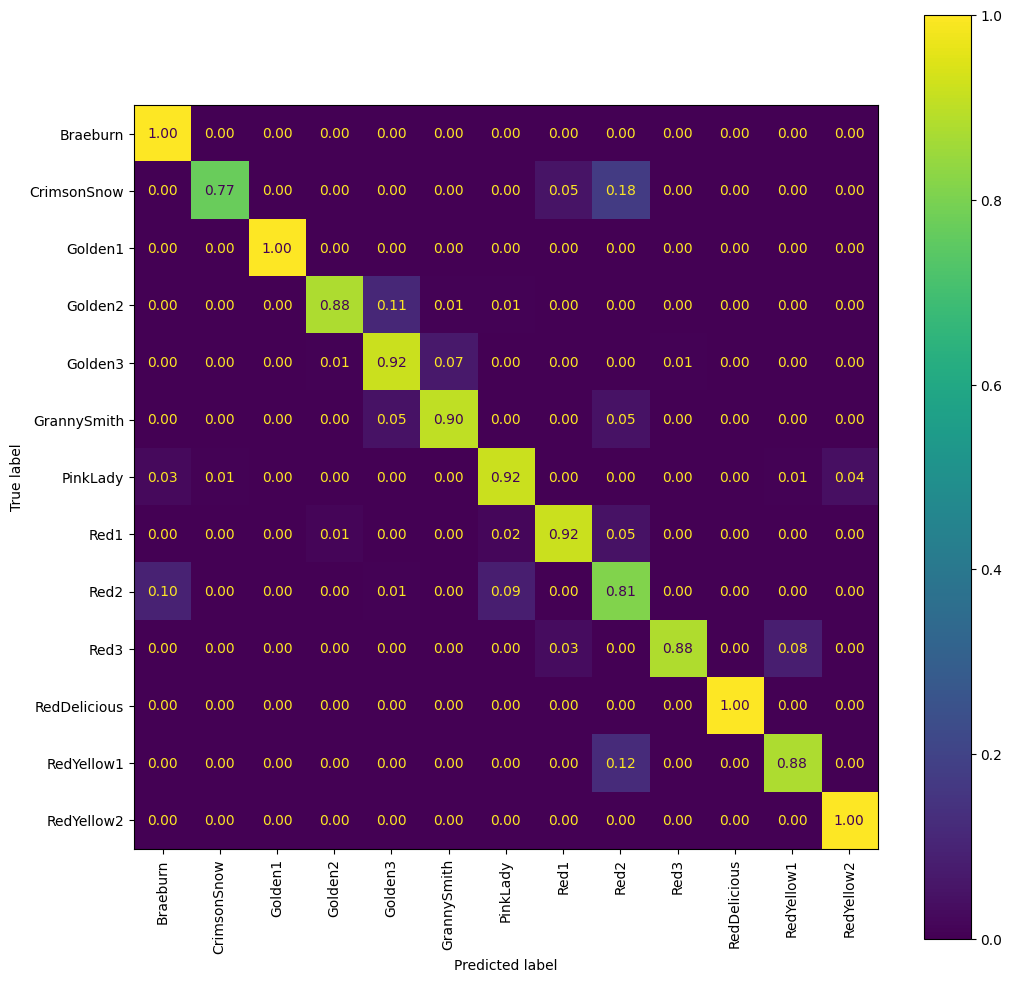

In [22]:
fig, ax = plt.subplots(figsize=(12, 12))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, normalize="true", values_format=".2f", xticks_rotation="vertical", ax=ax)
plt.show()

*Hay variedades perfectas (Golden1, RedDelicious, RedYellow2) y otras que se confunden entre sí, sobre todo entre las rojas: Red2 recibe muchas manzanas de otras variedades (su precision es solo del 68 %), las CrimsonSnow se escapan hacia otras rojas (77 % de recall) y Golden2, Red3 y RedYellow1 rondan el 88 %.*

*Para el análisis de errores buscamos automáticamente la confusión más frecuente (la pareja variedad real - variedad predicha con más errores) y vemos algunas de esas imágenes junto a ejemplos bien clasificados de ambas variedades:*

Confusión más frecuente: 26 CrimsonSnow predichas como Red2
CrimsonSnow predichas como Red2:


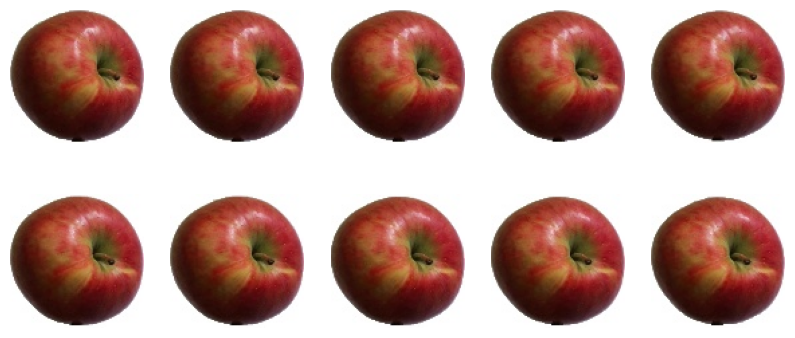

CrimsonSnow bien clasificadas:


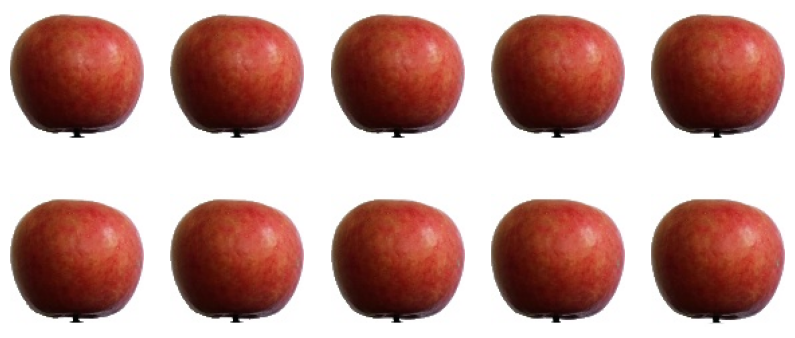

Red2 bien clasificadas:


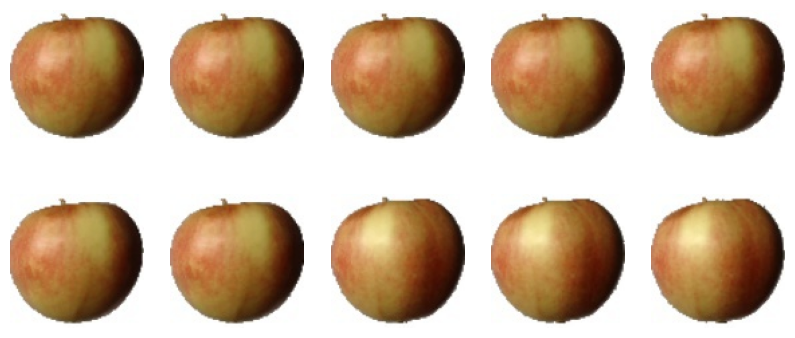

In [23]:
def peor_confusion(y_true, y_pred):
    cm = pd.crosstab(pd.Series(y_true, name="real"), pd.Series(y_pred, name="predicha"))
    errores = cm.stack()
    errores = errores[errores.index.get_level_values(0) != errores.index.get_level_values(1)]
    return errores.idxmax(), errores.max()

def muestra_confusion(y_true, y_pred, n = 10):
    (real, predicha), n_errores = peor_confusion(y_true, y_pred)
    print(f"Confusión más frecuente: {n_errores} {real} predichas como {predicha}")
    print(f"{real} predichas como {predicha}:")
    show_images_batch(X_test[(y_true == real) & (y_pred == predicha)][:n])
    print(f"{real} bien clasificadas:")
    show_images_batch(X_test[(y_true == real) & (y_pred == real)][:n])
    print(f"{predicha} bien clasificadas:")
    show_images_batch(X_test[(y_true == predicha) & (y_pred == predicha)][:n])

muestra_confusion(y_test, y_pred)

*Fíjate en las imágenes de los errores: son casi idénticas entre sí, fotogramas consecutivos de la misma manzana. Los errores no son independientes, vienen en bloques: si el modelo se equivoca con una vista concreta de una manzana se equivoca con todos sus fotogramas vecinos. Por la misma razón, nuestras 2134 imágenes de test equivalen en realidad a muchas menos imágenes "distintas".*

*Y la confusión es comprensible: las CrimsonSnow mal clasificadas son manzanas rojas con vetas amarillas muy parecidas a las Red2.*

## Fine-tuning (fase 2)

### Ejercicio 10

Partiendo del modelo ya entrenado en el Ejercicio 8 (la fase 1, con la cabeza ya ajustada), descongela **solo el último bloque** de la ResNet50V2: las capas cuyo nombre empieza por `conv5` y la capa final `post_bn`, dejando congeladas las de BatchNormalization. Vuelve a compilar el modelo con Adam y un learning rate de 1e-5, y muestra cuántas capas y parámetros entrenables hay ahora.

¿Por qué no hacemos el fine-tuning directamente, sin pasar antes por la fase 1? ¿Por qué el learning rate tan bajo? ¿Por qué hay que volver a compilar?

* *Sin la fase 1, la cabeza nueva tendría pesos aleatorios: sus errores (y gradientes) iniciales serían enormes y, al propagarse hacia la base descongelada, destrozarían los pesos preentrenados.*
* *Con un learning rate normal pasaría lo mismo: solo queremos **reajustar ligeramente** los pesos de ImageNet, no reaprenderlos (si no, caemos en el *olvido catastrófico*).*
* *Los cambios en `trainable` solo tienen efecto al compilar de nuevo el modelo.*

In [24]:
base_model.trainable = True
for layer in base_model.layers:
    es_ultimo_bloque = layer.name.startswith(("conv5", "post_bn"))
    if not es_ultimo_bloque or isinstance(layer, keras.layers.BatchNormalization):
        layer.trainable = False

print("Capas entrenables de la base:", sum(layer.trainable for layer in base_model.layers), "de", len(base_model.layers))

model.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-5),
              loss="sparse_categorical_crossentropy",
              metrics=["accuracy"])
model.summary()

Capas entrenables de la base: 25 de 190


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 100, 100, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ aumentado (Sequential)          │ (None, 100, 100, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 100, 100, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract (Subtract)             │ (None, 100, 100, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50v2 (Functional)         │ (None, 4, 4, 2048)     │    23,564,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 300)            │       614,700 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 300)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 13)             │         3,913 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 24,183,413 (92.25 MB)

 Trainable params: 15,569,013 (59.39 MB)

 Non-trainable params: 8,614,400 (32.86 MB)

*Ahora son entrenables unos 15,6 millones de parámetros: los de la cabeza y los del último bloque de la ResNet.*

### Ejercicio 11

Continúa el entrenamiento (fase 2) con batch_size 64, hasta 20 épocas y un EarlyStopping de patience 5, con la misma validación que en el Ejercicio 8. Muestra la evolución de las dos fases en una misma gráfica y compara la validación de ambas fases.

In [25]:
t_zero = time()
history_ft = model.fit(X_train_s,
                       y_train_num,
                       batch_size=batch_size,
                       validation_split=0.2, # Al no barajar, es exactamente la misma validación que en la fase 1
                       epochs=20,
                       callbacks=[early_stopping])
print(f"Tiempo de entrenamiento: {time() - t_zero:.0f} s")

Epoch 1/20
81/81 ━━━━━━━━━━━━━━━━━━━━ 131s 2s/step - accuracy: 0.9786 - loss: 0.0718 - val_accuracy: 0.9938 - val_loss: 0.0279
Epoch 2/20
81/81 ━━━━━━━━━━━━━━━━━━━━ 124s 2s/step - accuracy: 0.9873 - loss: 0.0362 - val_accuracy: 0.9953 - val_loss: 0.0117
Epoch 3/20
81/81 ━━━━━━━━━━━━━━━━━━━━ 103s 1s/step - accuracy: 0.9865 - loss: 0.0368 - val_accuracy: 0.9844 - val_loss: 0.0416
Epoch 4/20
81/81 ━━━━━━━━━━━━━━━━━━━━ 110s 1s/step - accuracy: 0.9898 - loss: 0.0317 - val_accuracy: 0.9953 - val_loss: 0.0083
Epoch 5/20
81/81 ━━━━━━━━━━━━━━━━━━━━ 86s 1s/step - accuracy: 0.9916 - loss: 0.0224 - val_accuracy: 0.9961 - val_loss: 0.0083
Epoch 6/20
81/81 ━━━━━━━━━━━━━━━━━━━━ 101s 1s/step - accuracy: 0.9927 - loss: 0.0218 - val_accuracy: 0.9992 - val_loss: 0.0048
Epoch 7/20
81/81 ━━━━━━━━━━━━━━━━━━━━ 106s 1s/step - accuracy: 0.9936 - loss: 0.0160 - val_accuracy: 0.9984 - val_loss: 0.0039
Epoch 8/20
81/81 ━━━━━━━━━━━━━━━━━━━━ 69s 853ms/step - accuracy: 0.9928 - loss: 0.0185 - val_accuracy: 0.9945 - 

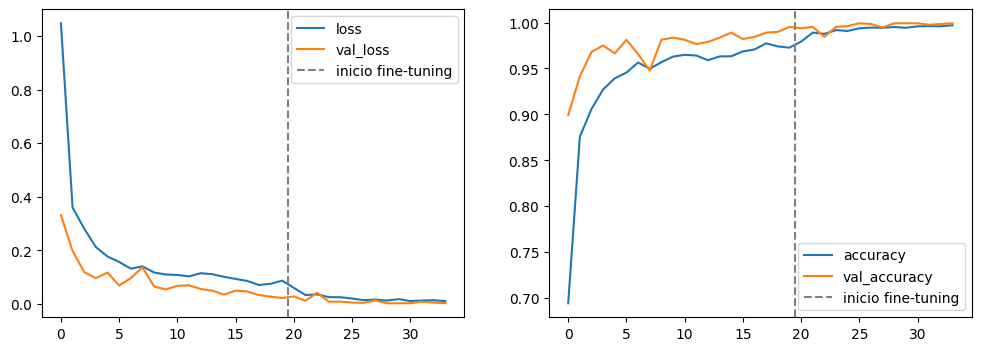

Fase 1 - mejor val_loss: 0.0221, val_accuracy en esa época: 0.9953
Fase 2 - mejor val_loss: 0.0022, val_accuracy en esa época: 0.9992


In [26]:
evol_ft = pd.concat([evol, pd.DataFrame(history_ft.history)], ignore_index=True)
fig, axs = plt.subplots(1, 2, figsize=(12, 4))
for ax, metrica in zip(axs, ["loss", "accuracy"]):
    evol_ft[[metrica, "val_" + metrica]].plot(ax=ax)
    ax.axvline(len(evol) - 0.5, color="grey", linestyle="--", label="inicio fine-tuning")
    ax.legend()
plt.show()

print(f"Fase 1 - mejor val_loss: {evol['val_loss'].min():.4f}, val_accuracy en esa época: {evol['val_accuracy'][evol['val_loss'].idxmin()]:.4f}")
evol_fase2 = pd.DataFrame(history_ft.history)
print(f"Fase 2 - mejor val_loss: {evol_fase2['val_loss'].min():.4f}, val_accuracy en esa época: {evol_fase2['val_accuracy'][evol_fase2['val_loss'].idxmin()]:.4f}")

*El fine-tuning continúa sin sobresaltos desde donde terminó la fase 1 (gracias al learning rate tan bajo) y la pérdida de validación baja un orden de magnitud, de 0,022 a 0,002, con un 99,9 % de accuracy en validación. Pero, como ya sabemos, esta validación está "contaminada" por los fotogramas vecinos y casi no deja margen para medir mejoras: tendremos que ver el test.*

### Ejercicio 12

Muestra la evaluación contra el test, el informe de clasificación y la matriz de confusión. Compara los resultados con los del ejercicio 9.

In [27]:
results_ft = model.evaluate(X_test, y_test_num)
print("test loss, test acc:", results_ft)

67/67 ━━━━━━━━━━━━━━━━━━━━ 15s 220ms/step - accuracy: 0.9450 - loss: 0.1802
test loss, test acc: [0.23491524159908295, 0.932052493095398]


67/67 ━━━━━━━━━━━━━━━━━━━━ 17s 234ms/step
              precision    recall  f1-score   support

    Braeburn       0.89      1.00      0.94       164
 CrimsonSnow       1.00      0.91      0.95       148
     Golden1       1.00      1.00      1.00       160
     Golden2       1.00      0.85      0.92       164
     Golden3       0.84      0.98      0.90       161
 GrannySmith       0.99      0.84      0.91       164
    PinkLady       0.88      0.95      0.92       152
        Red1       0.81      1.00      0.90       164
        Red2       0.83      0.81      0.82       164
        Red3       0.99      0.75      0.85       144
RedDelicious       1.00      1.00      1.00       166
  RedYellow1       0.98      0.98      0.98       164
  RedYellow2       0.99      1.00      0.99       219

    accuracy                           0.93      2134
   macro avg       0.94      0.93      0.93      2134
weighted avg       0.94      0.93      0.93      2134



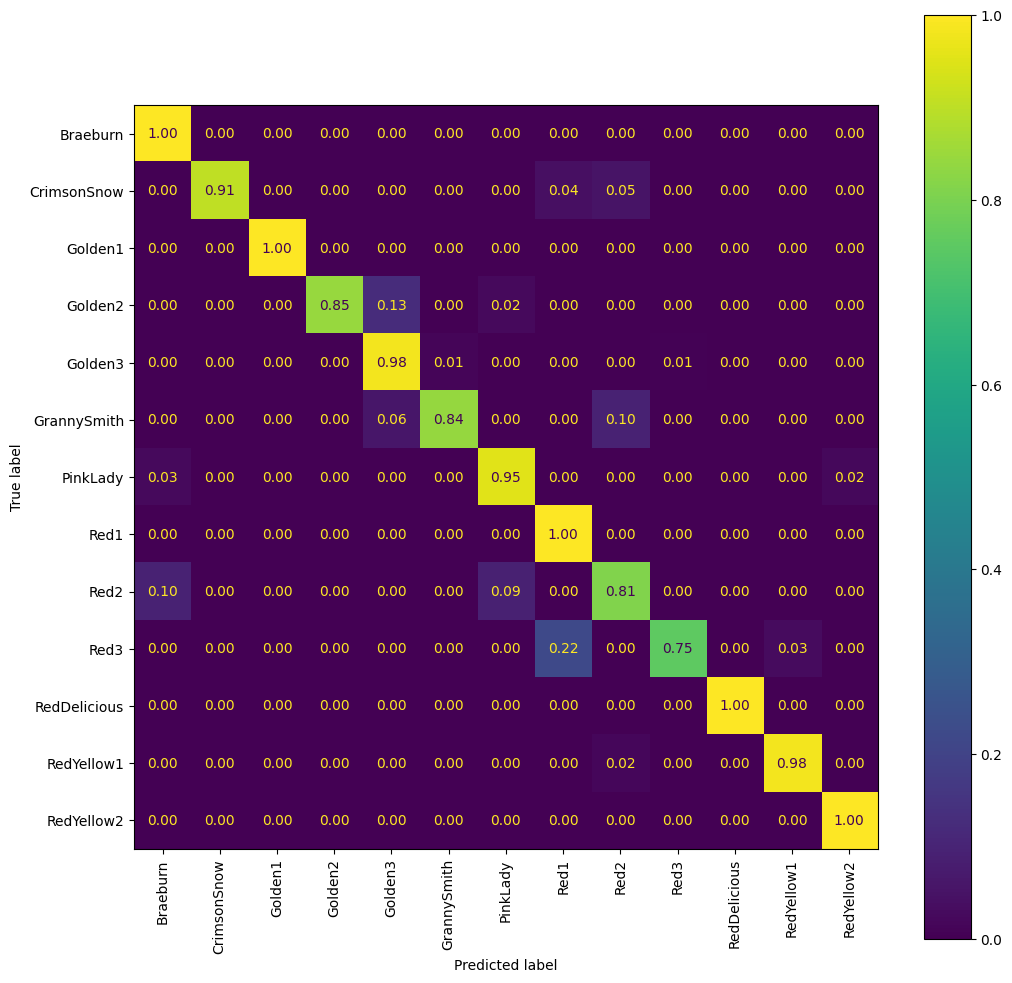

In [28]:
y_pred_ft = np.array([inverse_mapping[i] for i in np.argmax(model.predict(X_test), axis=1)])
print(classification_report(y_test, y_pred_ft))

fig, ax = plt.subplots(figsize=(12, 12))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_ft, normalize="true", values_format=".2f", xticks_rotation="vertical", ax=ax)
plt.show()

Confusión más frecuente: 32 Red3 predichas como Red1
Red3 predichas como Red1:


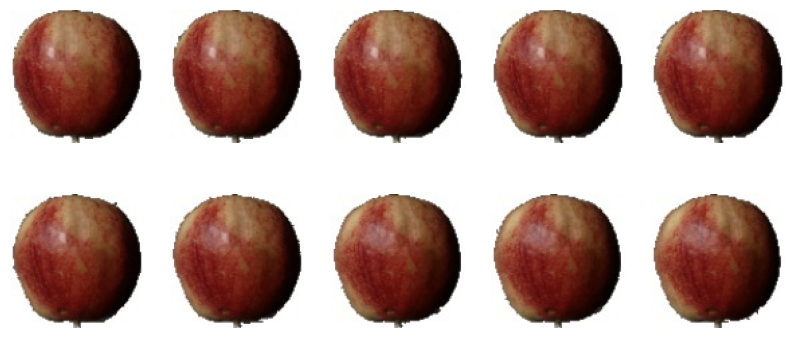

Red3 bien clasificadas:


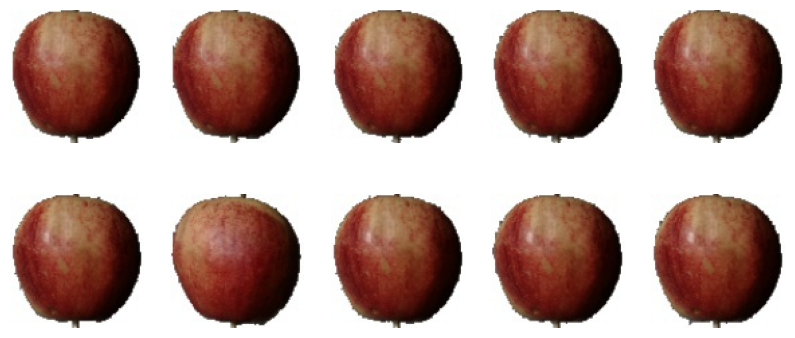

Red1 bien clasificadas:


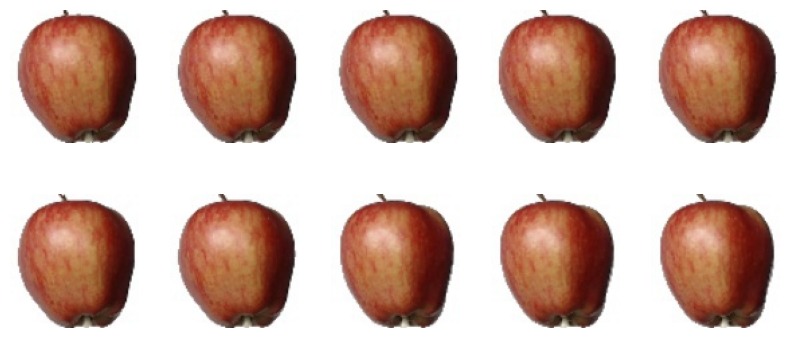

In [29]:
muestra_confusion(y_test, y_pred_ft)

*El fine-tuning sube la accuracy en test del 91,8 % al 93,2 % (1,4 puntos). La mejora no es uniforme: las CrimsonSnow pasan del 77 % al 91 % de recall y Red2 deja de ser el "cajón de sastre", pero ahora la confusión más frecuente es Red3 predicha como Red1 (Red3 baja del 88 % al 75 % de recall) y las Granny Smith empeoran algo. Mejoras pequeñas y repartidas, como era de esperar: ResNet50V2 ya traía buenas características para fotos de fruta y la fase 1 tenía poco margen.*

*En la matriz de confusión se ve que lo que falla son variedades realmente parecidas entre sí, lo que con imágenes de 100x100 tiene mérito.*

## EXTRA: ¿cuánto aporta el preentrenamiento?

Entrena la misma arquitectura **desde cero**: ResNet50V2 sin cabeza y **sin pesos preentrenados** (`weights=None`), con toda la red entrenable y la misma cabeza. Ojo: al no partir de pesos de ImageNet, aquí las capas de BatchNormalization sí tienen que aprender sus estadísticas, así que la base **no** se llama con `training=False`. Entrena con batch_size 64, hasta 15 épocas y EarlyStopping de patience 5 (ahora el entrenamiento es sensiblemente más largo, así que tómate un descanso) y compara con los dos modelos anteriores.

> Esto **no es fine-tuning**: sin los pesos preentrenados no hay nada que ajustar "finamente", es entrenar una red enorme desde cero con nuestros pocos datos.

In [30]:
model_cero, _ = prepare_model(weights=None)
print(f"Parámetros entrenables: {sum(np.prod(w.shape) for w in model_cero.trainable_weights):,}")

t_zero = time()
history_cero = model_cero.fit(X_train_s,
                              y_train_num,
                              batch_size=batch_size,
                              validation_split=0.2,
                              epochs=15,
                              callbacks=[keras.callbacks.EarlyStopping(patience=5, restore_best_weights=True)])
print(f"Tiempo de entrenamiento: {time() - t_zero:.0f} s")

Parámetros entrenables: 24,137,973
Epoch 1/15
81/81 ━━━━━━━━━━━━━━━━━━━━ 157s 2s/step - accuracy: 0.4848 - loss: 1.6221 - val_accuracy: 0.2272 - val_loss: 8.7422
Epoch 2/15
81/81 ━━━━━━━━━━━━━━━━━━━━ 138s 2s/step - accuracy: 0.8283 - loss: 0.5278 - val_accuracy: 0.4762 - val_loss: 3.2115
Epoch 3/15
81/81 ━━━━━━━━━━━━━━━━━━━━ 138s 2s/step - accuracy: 0.8975 - loss: 0.3324 - val_accuracy: 0.7635 - val_loss: 0.9125
Epoch 4/15
81/81 ━━━━━━━━━━━━━━━━━━━━ 138s 2s/step - accuracy: 0.9380 - loss: 0.1841 - val_accuracy: 0.3942 - val_loss: 6.0235
Epoch 5/15
81/81 ━━━━━━━━━━━━━━━━━━━━ 138s 2s/step - accuracy: 0.9397 - loss: 0.1710 - val_accuracy: 0.3255 - val_loss: 8.2853
Epoch 6/15
81/81 ━━━━━━━━━━━━━━━━━━━━ 138s 2s/step - accuracy: 0.9383 - loss: 0.2146 - val_accuracy: 0.3919 - val_loss: 12.9505
Epoch 7/15
81/81 ━━━━━━━━━━━━━━━━━━━━ 138s 2s/step - accuracy: 0.9573 - loss: 0.1243 - val_accuracy: 0.4372 - val_loss: 5.6151
Epoch 8/15
81/81 ━━━━━━━━━━━━━━━━━━━━ 139s 2s/step - accuracy: 0.9600 - los

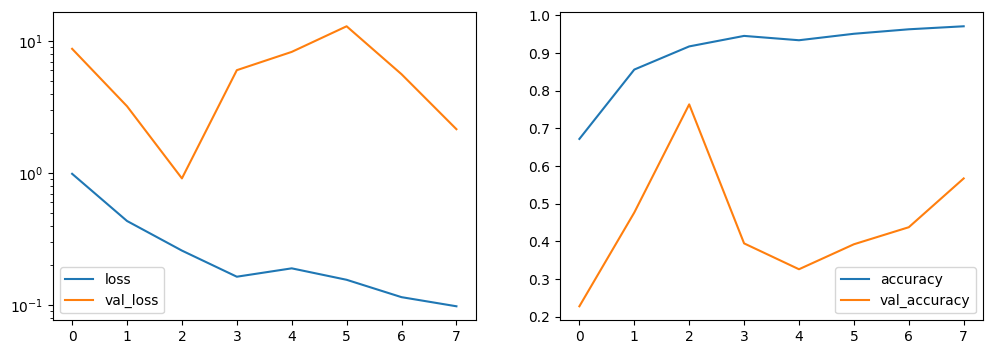

In [31]:
evol_cero = pd.DataFrame(history_cero.history)
fig, axs = plt.subplots(1, 2, figsize=(12, 4))
evol_cero[["loss", "val_loss"]].plot(ax=axs[0], logy=True)
evol_cero[["accuracy", "val_accuracy"]].plot(ax=axs[1])
plt.show()

In [32]:
results_cero = model_cero.evaluate(X_test, y_test_num)
pd.DataFrame({"modelo": ["Transfer learning (fase 1)", "Fine-tuning (fase 2)", "Desde cero"],
              "accuracy test": [results_tl[1], results_ft[1], results_cero[1]]}).round(4)

67/67 ━━━━━━━━━━━━━━━━━━━━ 15s 225ms/step - accuracy: 0.8059 - loss: 0.6995


,modelo,accuracy test
0,Transfer learning (fase 1),0.9175
1,Fine-tuning (fase 2),0.9321
2,Desde cero,0.7465


*Desde cero la cosa cambia mucho. Aunque la accuracy de train sube rápido (96 % en 8 épocas), la validación oscila de forma tremenda de una época a otra (del 23 % al 76 % y vuelta a bajar). Es lo habitual al entrenar una red de 24 millones de parámetros con solo 5000 imágenes: no tiene ningún conocimiento previo, es muy sensible a la inicialización y las estadísticas de BatchNorm aún no se han estabilizado. El EarlyStopping se queda con la época 3 y el modelo llega a un 74,6 % en test, frente al 91,8 % y el 93,2 % de los modelos preentrenados. Además cada época es bastante más lenta (unos 140 s frente a los 80-90 s de la fase 1), porque hay que calcular gradientes para toda la red.*

*Con mucha más paciencia (más épocas y un EarlyStopping más tolerante) una red desde cero acaba mejorando: en ediciones anteriores de este ejercicio, a 32x32 y con 17 épocas, se llegó a un 94 %. Pero ese es precisamente el valor del preentrenamiento: un buen modelo desde las primeras épocas, con un entrenamiento estable y barato, sin tener que pelearse con la inicialización.*